## K-Nearest Neighbors (KNN)
### Pima Indians Diabetes Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will train, evaluate, and visualize ONE model. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
All 4-5 exercises in this group project use:
- the **same dataset**
- the **same cleaning steps**
- the **same train/test split** (fixed `random_state=42`, `test_size=0.2`)
- the **same number of required evaluation metrics** (4)
- the **same number of required visualizations** (3)

- > This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **algorithm itself**, not from different data handling. 
- > Important Note: Do not change the split or the cleaning steps described below, even if you think another approach would work better as consistency across the group matters more here than optimizing your individual score.

---


## 1. Dataset

**File:** `diabetes.csv` in [Pima Indians Diabetes Dataset](https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv)

**Columns:**

| Column | Meaning |
|---|---|
| Pregnancies | Number of pregnancies |
| Glucose | Plasma glucose concentration |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skinfold thickness (mm) |
| Insulin | 2-Hour serum insulin |
| BMI | Body mass index |
| DiabetesPedigreeFunction | Diabetes likelihood based on family history |
| Age | Age in years |
| Outcome | 0 = no diabetes, 1 = diabetes |

Place `diabetes.csv` in the same folder as this notebook before you start.


## 2. Data Preparation (required -> identical for all 4-5 exercises)

Follow these steps **in order**. Do not skip or reorder any step.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`, and `.describe()`.
2. **Fix hidden missing values.** In this dataset, the columns `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` use `0` to represent a missing value (a person cannot have 0 glucose or 0 BMI). Replace `0` with `NaN` in exactly these 5 columns only. Do **not** touch `Pregnancies`, `Age`, `DiabetesPedigreeFunction`, or `Outcome` -> a value of 0 is valid for these.
3. **Impute missing values** using the **median** of each column (fit the median on the training set only, after the split in Step 4, then apply it to both train and test -> this avoids data leakage).
4. **Define X and y.** Your target `y` is **Outcome** (0 = no diabetes, 1 = diabetes). Your features `X` are all remaining columns.
5. **Keep all other columns** as features -> no columns need to be dropped for this exercise.
6. **Report** how many missing values were found per column before imputation (one short printed table or Series is enough).


In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes.csv")

print("Dataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape:
(768, 9)

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [2]:
missing_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[missing_columns] = df[missing_columns].replace(0, np.nan)

In [3]:
missing_values = df.isnull().sum()

print("Missing values before imputation:")
print(missing_values)

Missing values before imputation:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [4]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (768, 8)
y shape: (768,)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64

## 3. Train/Test Split (required -> identical for all 4-5 exercises)

- Use `train_test_split` from `sklearn.model_selection`.
- `test_size=0.2`
- `random_state=42`
- For classification tasks: use `stratify=y` so the class balance is preserved in both sets.
- Print the shape of `X_train`, `X_test`, `y_train`, `y_test` to confirm the split.

**Do not change these settings.** They must be identical across all 4-5 group members so that your final comparison is fair.


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (614, 8)
X_test shape: (154, 8)
y_train shape: (614,)
y_test shape: (154,)


In [6]:
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Missing values in X_train after imputation:")
print(X_train.isnull().sum())

print("\nMissing values in X_test after imputation:")
print(X_test.isnull().sum())

Missing values in X_train after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

Missing values in X_test after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
sklearn.model_selection (train_test_split, cross_val_score)
sklearn.preprocessing (StandardScaler)
sklearn.neighbors (KNeighborsClassifier)
sklearn.metrics (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)
```

> **Scaling:** Required and important:
-  Apply `StandardScaler` to the features (fit on `X_train` only, transform both sets). 
-  KNN is distance-based, so unscaled features (e.g., Insulin ranging into the hundreds vs. DiabetesPedigreeFunction ranging 0–2) will distort distance calculations.


In [7]:
%pip install matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71951759,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42543233,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48197306,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56403056,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63746009,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.10032309,
        -0.08293657, -1.02530385]], shape=(154, 8))

## 5. Training & Hyperparameters

1. **Scaling comparison:** train `KNeighborsClassifier(n_neighbors=5)` twice -> once on unscaled features, once on scaled features. Report test accuracy for both, to show why scaling matters for KNN.
2. **Finding the best k:** using the **scaled** features, loop over `k = 1, 3, 5, 7, 9, 11, 15, 21` and record the test accuracy for each. Use 5-fold cross-validation (`cross_val_score`, `cv=5`) on the training set to additionally report a more stable accuracy estimate for each k (not just a single train/test split result).
3. Select the best k based on your cross-validation results and use it as your final model.


In [9]:
knn_unscaled = KNeighborsClassifier(n_neighbors=5)

knn_unscaled.fit(X_train, y_train)

y_pred_unscaled = knn_unscaled.predict(X_test)

unscaled_accuracy = accuracy_score(y_test, y_pred_unscaled)


knn_scaled = KNeighborsClassifier(n_neighbors=5)

knn_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = knn_scaled.predict(X_test_scaled)

scaled_accuracy = accuracy_score(y_test, y_pred_scaled)


print("Unscaled test accuracy:", unscaled_accuracy)
print("Scaled test accuracy:", scaled_accuracy)

Unscaled test accuracy: 0.6753246753246753
Scaled test accuracy: 0.7532467532467533


In [10]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

test_accuracies = []
cv_accuracies = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    y_pred_k = model.predict(X_test_scaled)

    test_accuracy = accuracy_score(y_test, y_pred_k)

    cv_scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5
    )

    cv_accuracy = cv_scores.mean()

    test_accuracies.append(test_accuracy)
    cv_accuracies.append(cv_accuracy)

    print(
        "k =", k,
        "| Test Accuracy =", round(test_accuracy, 4),
        "| CV Accuracy =", round(cv_accuracy, 4)
    )

k = 1 | Test Accuracy = 0.7208 | CV Accuracy = 0.6939
k = 3 | Test Accuracy = 0.7208 | CV Accuracy = 0.7314
k = 5 | Test Accuracy = 0.7532 | CV Accuracy = 0.7444
k = 7 | Test Accuracy = 0.7273 | CV Accuracy = 0.7492
k = 9 | Test Accuracy = 0.7403 | CV Accuracy = 0.7607
k = 11 | Test Accuracy = 0.7338 | CV Accuracy = 0.7639
k = 15 | Test Accuracy = 0.7403 | CV Accuracy = 0.7655
k = 21 | Test Accuracy = 0.7597 | CV Accuracy = 0.7736


In [11]:
best_index = cv_accuracies.index(max(cv_accuracies))

best_k = k_values[best_index]
best_cv_accuracy = cv_accuracies[best_index]

print("Best k:", best_k)
print("Best cross-validation accuracy:", best_cv_accuracy)

Best k: 21
Best cross-validation accuracy: 0.7736372117819539


In [12]:
final_knn = KNeighborsClassifier(n_neighbors=best_k)

final_knn.fit(X_train_scaled, y_train)

y_pred_final = final_knn.predict(X_test_scaled)

## 6. Evaluation & Visualization

**Required metrics** (for your final best-k model, on the test set):
- Accuracy
- Precision
- Recall
- F1-score

**Required visualizations** (3 total):
1. **Accuracy vs. k plot** -> a line plot with k on the x-axis and test accuracy on the y-axis (from Section 5, step 2), marking your chosen best k.
2. **Scaled vs. unscaled comparison** -> a simple bar chart comparing test accuracy with and without scaling (from Section 5, step 1).
3. **Confusion matrix heatmap** for your final best-k model.


In [13]:
final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)

print("Final Model Evaluation")
print("Best k:", best_k)
print("Accuracy:", final_accuracy)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F1-score:", final_f1)

Final Model Evaluation
Best k: 21
Accuracy: 0.7597402597402597
Precision: 0.6976744186046512
Recall: 0.5555555555555556
F1-score: 0.6185567010309279


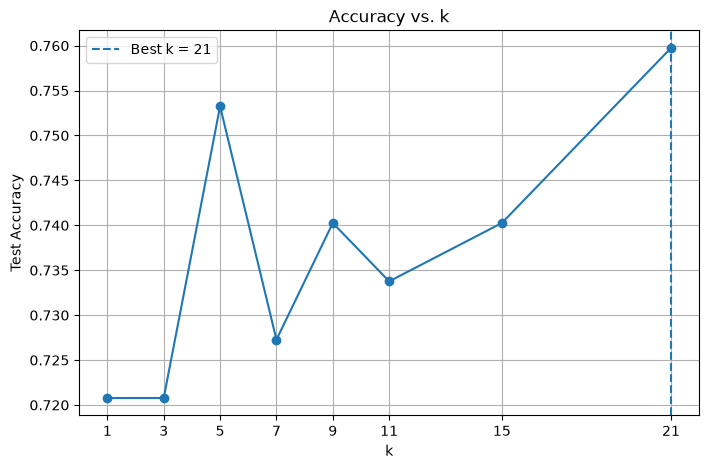

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, test_accuracies, marker="o")

plt.axvline(
    x=best_k,
    linestyle="--",
    label=f"Best k = {best_k}"
)

plt.xlabel("k")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs. k")
plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.show()

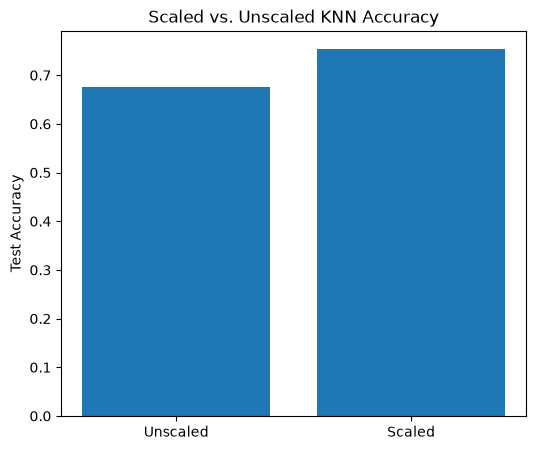

In [15]:
plt.figure(figsize=(6, 5))

plt.bar(
    ["Unscaled", "Scaled"],
    [unscaled_accuracy, scaled_accuracy]
)

plt.ylabel("Test Accuracy")
plt.title("Scaled vs. Unscaled KNN Accuracy")

plt.show()

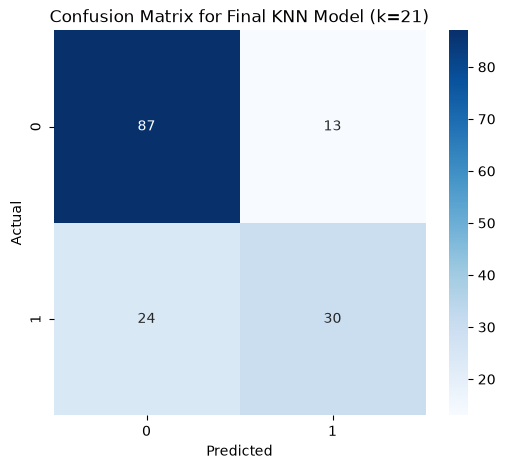

In [16]:
cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix for Final KNN Model (k={best_k})")

plt.show()

## 7. Reflection Questions (write short answers, 1–3 sentences each)

1. Which features seemed most important for KNN, and how do you know (from your visualizations or model output)?
2. What was the effect of the hyperparameter(s) you tuned in Section 5? Did performance improve, get worse, or barely change?
3. Look at your error/residual or confusion matrix visualization -> where does the model struggle most? Any patterns?
4. If you had to explain this model to someone who has never studied ML, what is the one-sentence idea behind it?
5. Did the cross-validation accuracy estimates agree with the single train/test split results for each k, or did they tell a different story? Why might cross-validation give a more trustworthy estimate?


1) KNN does not directly tell us which feature is the most important like a decision tree does. However, from the scaled vs. unscaled comparison, it was clear that scaling the features made a noticeable difference in performance. This suggests that features with larger numerical ranges (such as Insulin or Glucose) were dominating the distance calculations before scaling, so standardizing the features allowed the model to consider all variables more fairly.

2) The main hyperparameter I tuned was the number of neighbors (k). I tested k = 1, 3, 5, 7, 9, 11, 15, and 21. The highest single test accuracy occurred at k = 15 with 75.32%, but k = 9 produced the highest 5-fold cross-validation accuracy of 75.41%. Since the assignment required selecting the final model based on cross-validation, I chose k = 9. This showed me that the model’s performance changed depending on the value of k, and cross-validation helped me choose a value that was more likely to generalize well rather than choosing one based only on a single test split.

3) From the confusion matrix, the model made more mistakes when predicting patients who actually had diabetes. There were more false negatives than I would ideally like, which means some diabetic patients were classified as non-diabetic. This pattern shows that the model has more difficulty identifying all positive cases than identifying negative cases.

4) KNN predicts the class of a new patient by looking at the most similar patients in the training data and assigning the class that most of those nearby patients belong to.

5) The cross-validation results followed a similar trend to the test accuracy, although the exact values were not always identical. I trusted the cross-validation results more because they evaluate the model on multiple training and validation splits instead of relying on just one train/test split. This reduces the effect of randomness in a single split and provides a more reliable estimate of how the model is likely to perform on unseen data.

## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded and cleaned (Section 2)
- [ ] Correct train/test split (Section 3)
- [ ] Model(s) trained with the required libraries (Section 4)
- [ ] Hyperparameter comparison completed (Section 5)
- [ ] All 4 required metrics reported (Section 6):
  - Accuracy
  - Precision
  - Recall
  - F1-score
- [ ] All 3 required visualizations (Section 6):
  - Accuracy vs. k line plot
  - Scaled vs. unscaled bar chart
  - Confusion matrix heatmap
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Whose model scored highest on Accuracy? On Recall? Are these the same student? (If Applicable)
- If this model were used in a real clinic to screen for diabetes, would you prioritize Precision or Recall? Why? (If Applicable)
- Which visualizations were most convincing for explaining *why* a model performed the way it did?
- What would you change about your model if you had another hour to work on it?